# 11 경보 평가기 — 첫 단계 실제 결과

고정 무경보/항상 경보 기준으로 평가기를 점검합니다. 학습된 모델의 예측 성능이 아닙니다. validation만 사용하고 holdout은 점수화하지 않습니다.

In [1]:
from pathlib import Path
import sys, json
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
import pandas as pd
from IPython.display import display, Image
from src.common import TABLES, CFG
assert Path(sys.executable).resolve()==Path(CFG['python']).resolve()
print('실제 실행:',sys.executable)

실제 실행: C:\Users\fl27\anaconda3\envs\phm2018\python.exe


## 실제 이벤트 커버리지와 전체 점수화 대상

기록 이벤트/입력 있는 이벤트/검출 이벤트를 구분합니다. 미확인 라벨을 정상으로 바꾸지 않습니다.

,scheme,feature_set,baseline,recorded_events,scorable_events,available_events,detected_events,alarm_episodes,available_anchors,observed_support_raw,alarms_MATCHED,alarms_KNOWN_NEGATIVE_START,alarms_POSITIVE_UNMATCHED,alarms_UNKNOWN_START,alarms_LATE_OR_EXCLUDED_START,recall_recorded,recall_available,alarm_episodes_per_10000_raw
0,group,A,always_alarm,164,164,73,16,92002,1281388,72980584.0,16,31851,0,60132,3,0.097561,0.219178,12.606367
1,group,A,no_alarm,164,164,73,0,0,1281388,72980584.0,0,0,0,0,0,0.000000,0.000000,0.000000
2,group,B,always_alarm,164,164,73,19,90059,823731,45706136.0,18,31359,0,58680,2,0.115854,0.260274,19.703919
3,group,B,no_alarm,164,164,73,0,0,823731,45706136.0,0,0,0,0,0,0.000000,0.000000,0.000000
4,group,C,always_alarm,164,164,48,16,19605,202586,11305806.0,16,9174,0,10414,1,0.097561,0.333333,17.340648
5,group,C,no_alarm,164,164,48,0,0,202586,11305806.0,0,0,0,0,0,0.000000,0.000000,0.000000
6,temporal,A,always_alarm,232,232,98,25,63590,1061290,60897220.0,26,1551,0,62008,5,0.107759,0.255102,10.442184
7,temporal,A,no_alarm,232,232,98,0,0,1061290,60897220.0,0,0,0,0,0,0.000000,0.000000,0.000000
8,temporal,B,always_alarm,232,232,95,31,62044,745401,42090658.0,31,1494,0,60517,2,0.133621,0.326316,14.740563
9,temporal,B,no_alarm,232,232,95,0,0,745401,42090658.0,0,0,0,0,0,0.000000,0.000000,0.000000


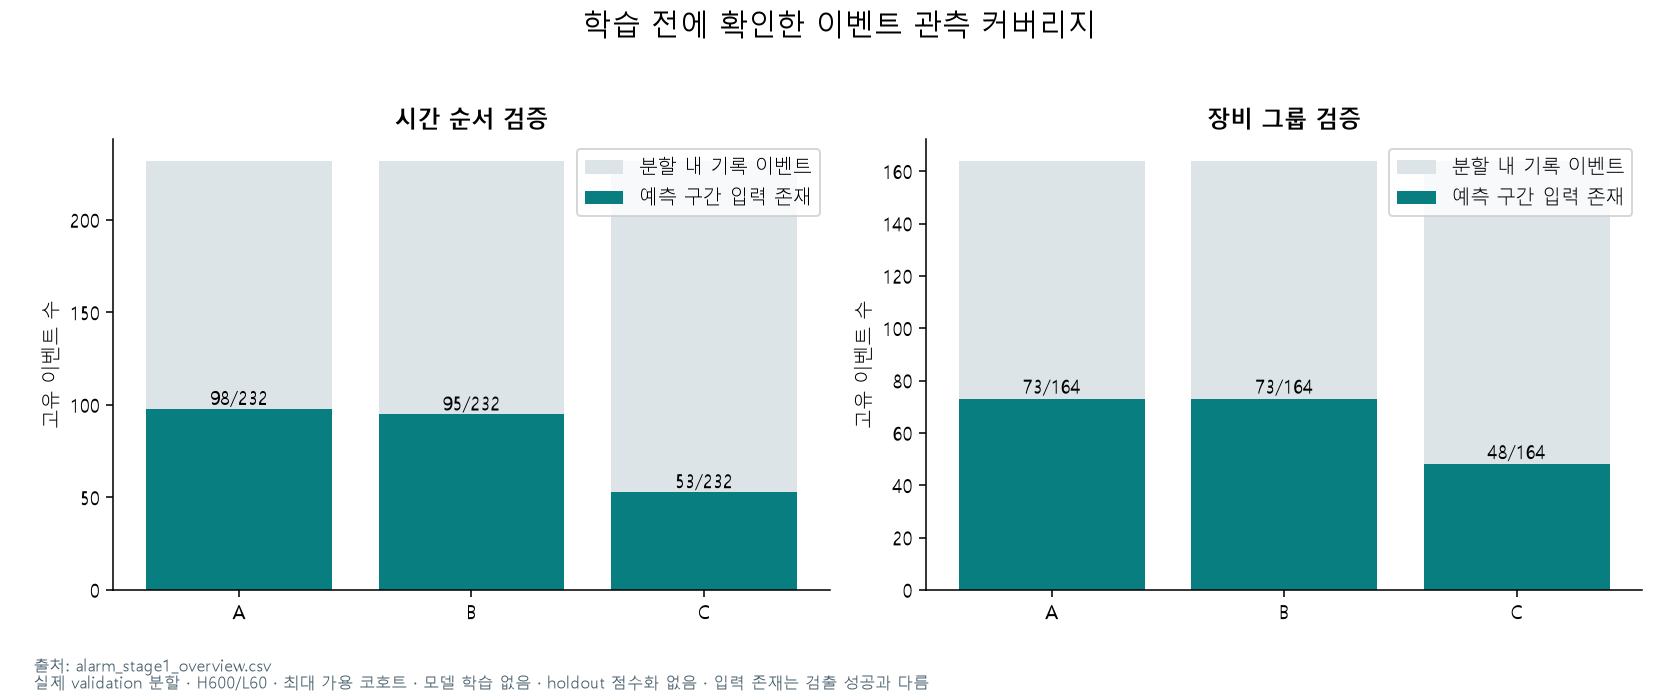

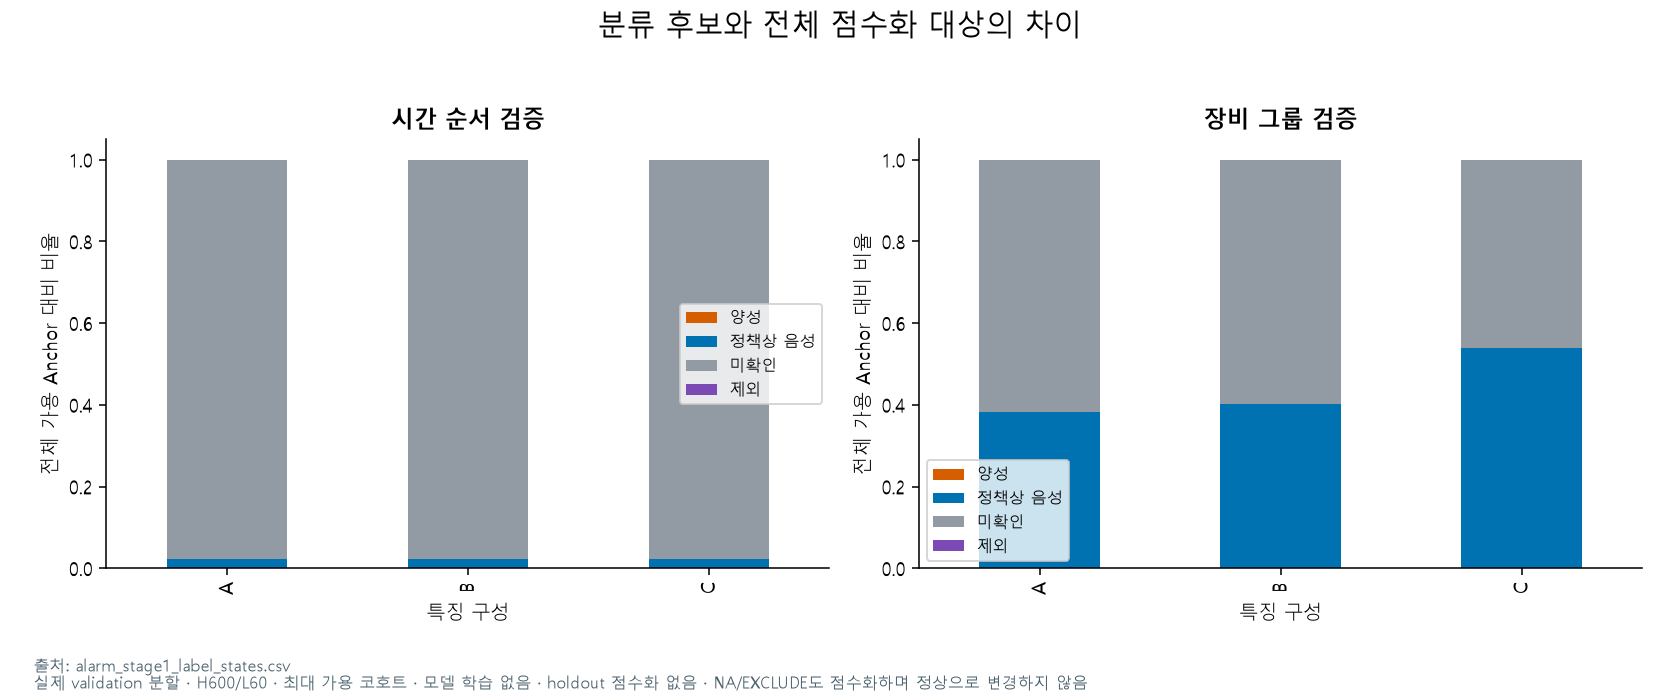

In [2]:
overview=pd.read_parquet(TABLES/'alarm_stage1_overview.parquet')
display(overview)
display(Image(filename=str(ROOT/'outputs/figures/alarm_stage1/event_coverage.png')))
display(Image(filename=str(ROOT/'outputs/figures/alarm_stage1/scoring_population.png')))

## 경보 부담과 고정 기준

항상 경보의 첫 발행이 예측 창보다 이르면 새 검출로 소급하지 않습니다. 명목 관측 지지길이는 실가동시간이 아닙니다.

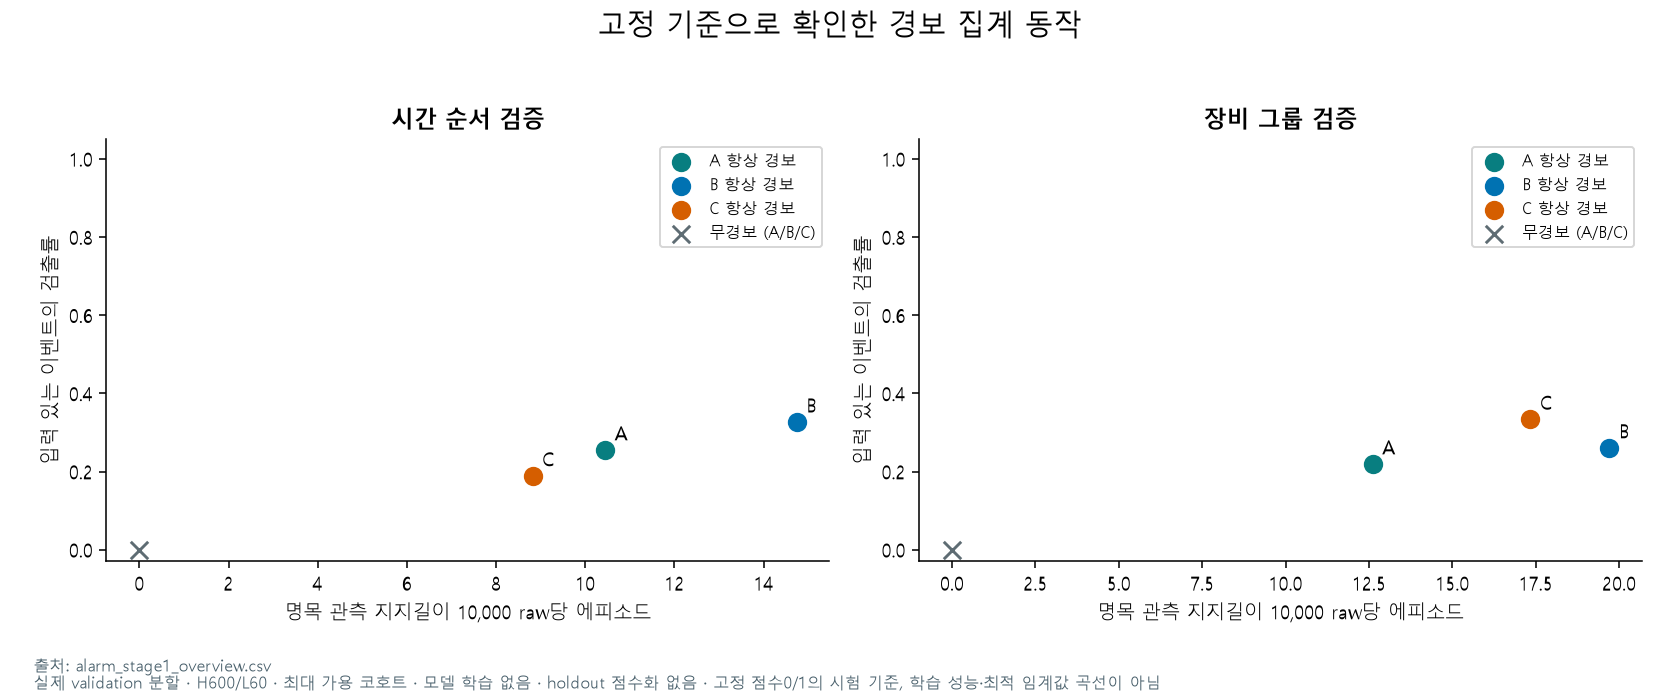

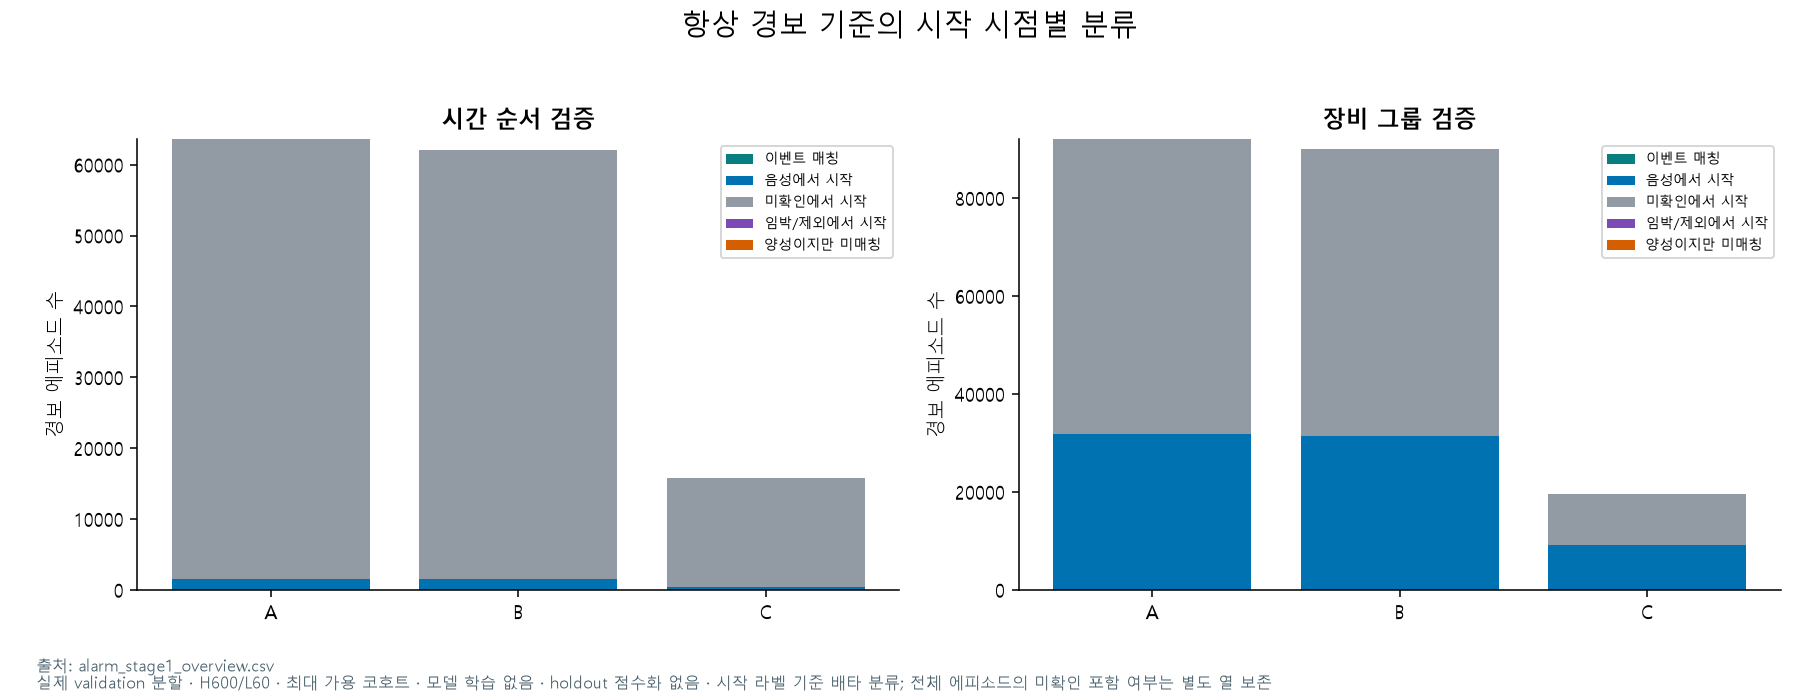

,Tool,episode_id,start,end,anchors,start_label,contains_unknown,contains_exclude,segment_id,matched_event_count,category,scheme,split,feature_set,baseline
0,01M01,01M01-alarm-000001,27136560,27136920,7,2,True,False,7640,0,UNKNOWN_START,temporal,validation,A,always_alarm
1,01M01,01M01-alarm-000002,27137040,27137100,2,2,True,False,7641,0,UNKNOWN_START,temporal,validation,A,always_alarm
2,01M01,01M01-alarm-000003,27141480,27142200,13,2,True,False,7642,0,UNKNOWN_START,temporal,validation,A,always_alarm
3,01M01,01M01-alarm-000004,27142380,27146640,72,2,True,False,7643,0,UNKNOWN_START,temporal,validation,A,always_alarm
4,01M01,01M01-alarm-000005,27147480,27148200,13,2,True,False,7644,0,UNKNOWN_START,temporal,validation,A,always_alarm
5,01M01,01M01-alarm-000006,27148320,27148620,6,2,True,False,7645,0,UNKNOWN_START,temporal,validation,A,always_alarm
6,01M01,01M01-alarm-000007,27148740,27148800,2,2,True,False,7646,0,UNKNOWN_START,temporal,validation,A,always_alarm
7,01M01,01M01-alarm-000008,27150420,27151140,13,2,True,False,7647,0,UNKNOWN_START,temporal,validation,A,always_alarm
8,01M01,01M01-alarm-000009,27151320,27152340,18,2,True,False,7648,0,UNKNOWN_START,temporal,validation,A,always_alarm
9,01M01,01M01-alarm-000010,27153300,27154020,13,2,True,False,7649,0,UNKNOWN_START,temporal,validation,A,always_alarm


In [3]:
display(Image(filename=str(ROOT/'outputs/figures/alarm_stage1/baseline_checks.png')))
display(Image(filename=str(ROOT/'outputs/figures/alarm_stage1/alarm_categories.png')))
episodes=pd.read_parquet(TABLES/'alarm_stage1_episodes.parquet')
display(episodes.head(12))

## 실제 고장 구간과 검출 근거

,event_id,Tool,fault_type,fault_time,tagged,eligible_anchors,available,detected,status,first_alarm,lead_raw,late_alarm_episodes,scheme,split,feature_set,baseline
477,03M02-high-a481f9abd9a5,03M02,high,27886310.0,False,0,False,False,NO_INPUT,NaN,NaN,0,temporal,validation,B,always_alarm
478,03M02-low-87ba7cdaecd4,03M02,low,27886398.0,False,0,False,False,NO_INPUT,NaN,NaN,0,temporal,validation,B,always_alarm
479,03M02-low-1803f613d250,03M02,low,27899460.0,False,0,False,False,NO_INPUT,NaN,NaN,0,temporal,validation,B,always_alarm
480,03M02-low-b2a0113c3738,03M02,low,27922370.0,False,0,False,False,NO_INPUT,NaN,NaN,0,temporal,validation,B,always_alarm
481,03M02-low-9bef5552950a,03M02,low,27954278.0,False,9,True,False,MISSED,NaN,NaN,0,temporal,validation,B,always_alarm
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
563,03M02-low-62797d3dacd5,03M02,low,35416716.0,False,0,False,False,NO_INPUT,NaN,NaN,0,temporal,validation,B,always_alarm
564,03M02-low-67358af2d4d4,03M02,low,35476948.0,False,0,False,False,NO_INPUT,NaN,NaN,0,temporal,validation,B,always_alarm
565,03M02-low-2b97f813612f,03M02,low,35516362.0,False,3,True,True,DETECTED,35516160.0,202.0,0,temporal,validation,B,always_alarm
566,03M02-low-32bdfbc7f4a3,03M02,low,35614502.0,False,5,True,True,DETECTED,35614140.0,362.0,0,temporal,validation,B,always_alarm


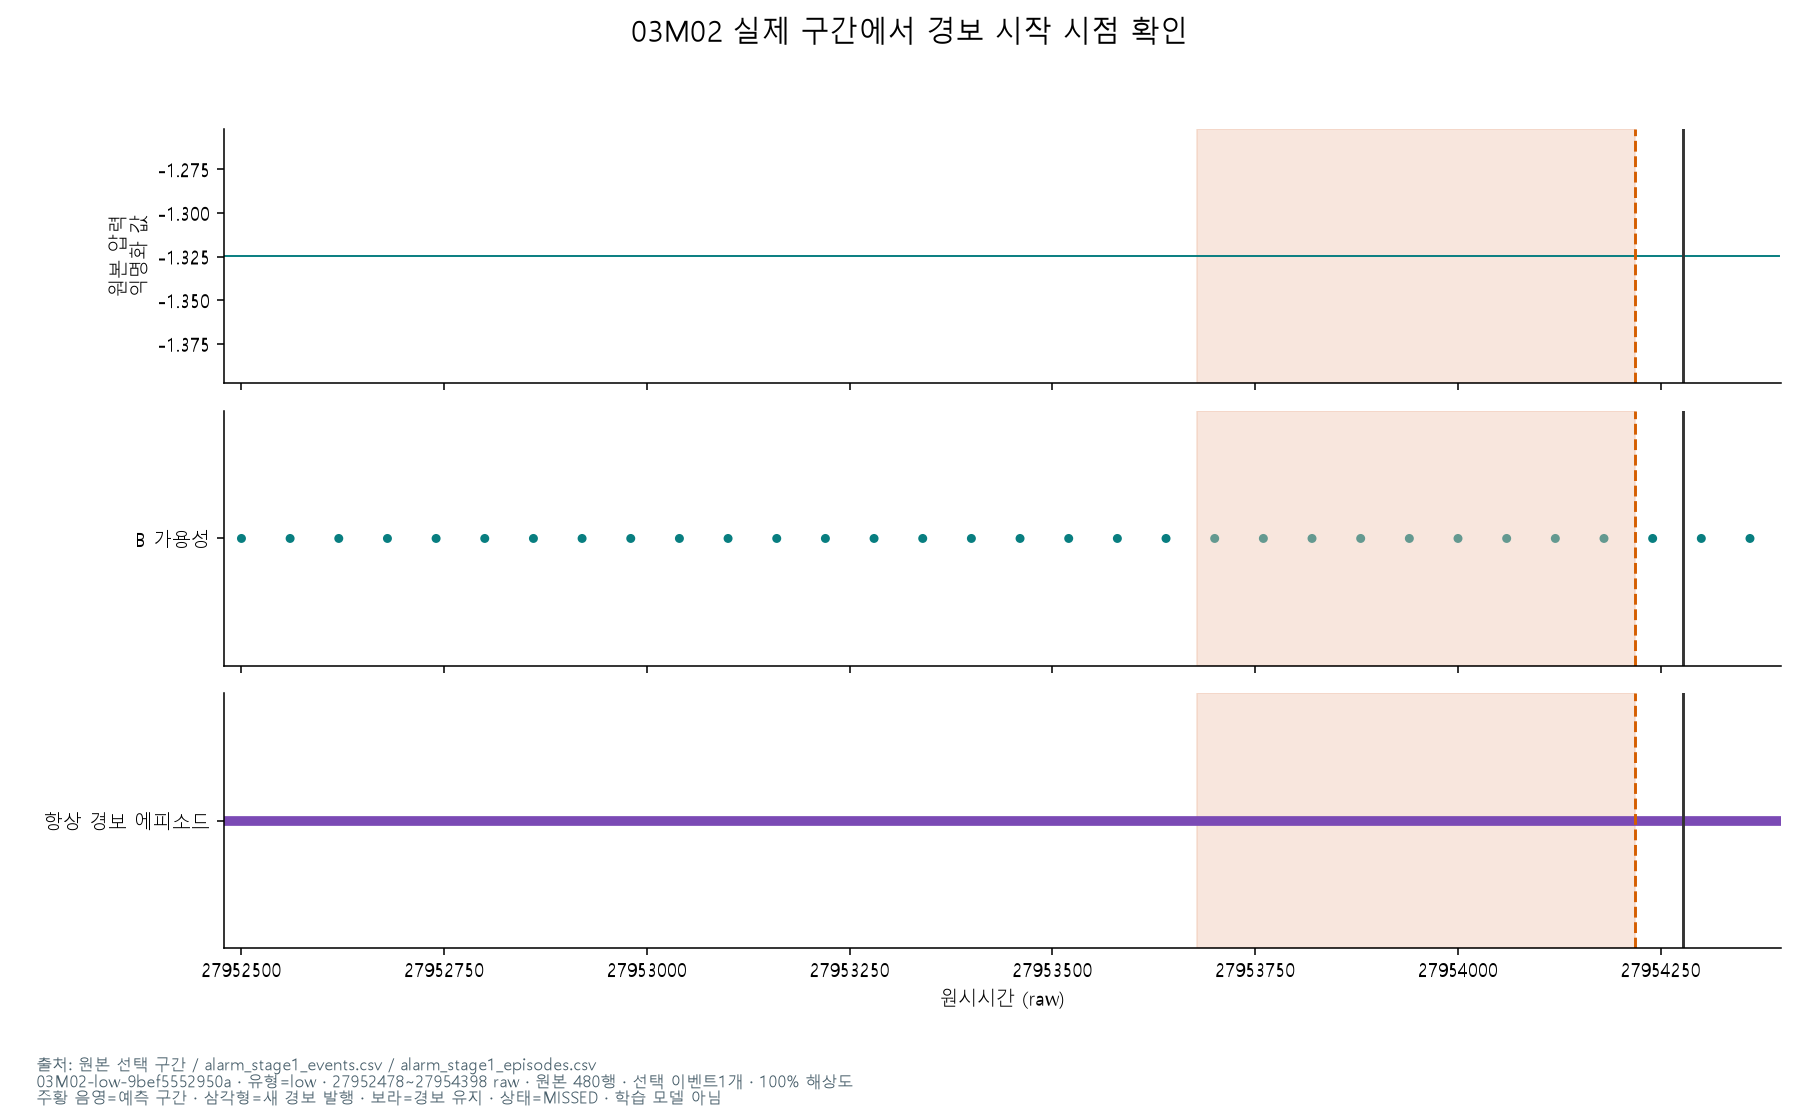

In [4]:
events=pd.read_parquet(TABLES/'alarm_stage1_events.parquet')
selected=events[events.Tool.eq('03M02') & events.scheme.eq('temporal') & events.feature_set.eq('B') & events.baseline.eq('always_alarm')]
display(selected)
display(Image(filename=str(ROOT/'outputs/figures/alarm_stage1/actual_event.png')))

## 학습 전용 특징과 평가 전용 라벨 분리

아래 셀은 점수를 학습하지 않고 실제 첫 배치의 입력 계약만 확인합니다.

In [5]:
from src.pretraining import iter_scoring_batches
X, metadata=next(iter_scoring_batches('temporal','validation','B',600,tool='03M02'))
assert 'audit_label' not in X and 'time' not in X
print('입력:',X.shape,'평가 metadata:',metadata.shape)
display(X.head())
display(metadata.head())
checks=json.loads((ROOT/'outputs/validation/alarm_stage1_checks.json').read_text(encoding='utf-8'))
assert all(c['passed'] for c in checks['checks'])
print('실제 분모/스키마/경계 검사:',len(checks['checks']))

입력: (6700, 32) 평가 metadata: (6700, 6)


,recipe,stage,FLOWCOOLPRESSURE__current,FLOWCOOLFLOWRATE__current,IONGAUGEPRESSURE__current,ETCHBEAMCURRENT__current,ETCHBEAMVOLTAGE__current,ETCHSUPPRESSORCURRENT__current,FLOWCOOLPRESSURE__mean_300,FLOWCOOLPRESSURE__std_300,...,ETCHBEAMCURRENT__min_300,ETCHBEAMCURRENT__max_300,ETCHBEAMVOLTAGE__mean_300,ETCHBEAMVOLTAGE__std_300,ETCHBEAMVOLTAGE__min_300,ETCHBEAMVOLTAGE__max_300,ETCHSUPPRESSORCURRENT__mean_300,ETCHSUPPRESSORCURRENT__std_300,ETCHSUPPRESSORCURRENT__min_300,ETCHSUPPRESSORCURRENT__max_300
0,249.0,1.0,0.179928,0.523204,0.809809,1.297428,1.496196,1.160650,0.052296,0.393241,...,-1.272325,3.686514,0.834554,1.126056,-1.222130,1.498044,0.373842,1.090988,-1.417021,1.167129
1,249.0,1.0,0.179182,0.537813,0.809809,1.301796,1.496840,1.161149,0.178587,0.003496,...,-1.271769,3.686514,1.347969,0.565377,-1.219263,1.498044,0.888111,0.639378,-1.416025,1.167129
2,249.0,1.0,0.181040,0.523204,0.809809,1.308229,1.497027,1.147441,0.179800,0.001101,...,0.900755,1.323238,1.496572,0.000621,1.495455,1.498044,1.124656,0.057448,0.925659,1.167129
3,249.0,1.0,0.181040,0.523204,0.809809,1.304257,1.496472,1.141211,0.179969,0.001269,...,1.216186,1.323238,1.496710,0.000671,1.495548,1.498137,1.149088,0.014461,1.064462,1.167129
4,249.0,1.0,0.182911,0.530509,0.809809,1.305609,1.496472,1.135730,0.180471,0.001165,...,1.293776,1.323238,1.496783,0.000628,1.495641,1.498137,1.148310,0.009341,1.128752,1.166131


,Tool,time,segment_id,source_row,source_file,audit_label
0,03M02,27749640,14412,7855,data/cache/analysis/03M02/anchors-0015.parquet,0
1,03M02,27749700,14412,7856,data/cache/analysis/03M02/anchors-0015.parquet,0
2,03M02,27749760,14412,7857,data/cache/analysis/03M02/anchors-0015.parquet,0
3,03M02,27749820,14412,7858,data/cache/analysis/03M02/anchors-0015.parquet,0
4,03M02,27749880,14412,7859,data/cache/analysis/03M02/anchors-0015.parquet,0


실제 분모/스키마/경계 검사: 72


## CUDA 우선 학습 준비

장치 인식/빌드 확인 결과입니다. 실제 GPU 학습·VRAM 사용 검증은 다음 단계에서 수행합니다.

In [6]:
profile=json.loads((ROOT/'outputs/validation/local_compute_profile.json').read_text(encoding='utf-8'))
display(profile)
print('학습 설정:',json.loads((ROOT/'config/local_compute.json').read_text(encoding='utf-8')))
assert profile['training_smoke_test_performed'] is False

{'date': '2026-11-05',
 'gpu_query': 'NVIDIA GeForce RTX 3060 Laptop GPU, 6144 MiB, 4631 MiB, 546.92',
 'ram_total_bytes': 33492262912,
 'ram_available_bytes': 20451991552,
 'physical_cpu_cores': 8,
 'logical_cpu_cores': 16,
 'xgboost_version': '3.2.0',
 'xgboost_build': {'BUILTIN_PREFETCH_PRESENT': False,
  'CUDA_VERSION': [12, 9],
  'DEBUG': False,
  'MM_PREFETCH_PRESENT': True,
  'THRUST_VERSION': [2, 8, 2],
  'USE_CUDA': True,
  'USE_DLOPEN_NCCL': False,
  'USE_FEDERATED': False,
  'USE_NCCL': False,
  'USE_NVCOMP': False,
  'USE_OPENMP': True,
  'USE_RMM': False,
  'libxgboost': 'C:\\Users\\fl27\\anaconda3\\envs\\phm2018\\Lib\\site-packages\\xgboost\\lib\\xgboost.dll'},
 'cuInit_status': 0,
 'cuDeviceGetCount_status': 0,
 'cuda_devices': 1,
 'cuDriverGetVersion_status': 0,
 'cuda_driver_api_version': 12030,
 'training_smoke_test_performed': False,
 'note': '장치/드라이버 탐지와 CUDA 빌드 확인. 실제 XGBoost CUDA 학습 및 VRAM 요구량은 다음 단계에서 검증.'}

학습 설정: {'training_device': 'cuda:0', 'training_tree_method': 'hist', 'training_cpu_threads': 12, 'io_threads': 4, 'parallel_training_trials': 1, 'initial_max_bin': 128, 'host_memory_budget_gib': 12, 'gpu_reserve_mib': 1024, 'gpu_training_smoke_test_required': True, 'silent_cpu_fallback_allowed': False, 'note': '사용자 CUDA 우선 지시 반영. GPU 실제 학습 검증은 2단계에서 수행. 드라이버/패키지 자동 변경 없음.'}
